# Arrow-of-time response: current state of $Q$, $Q'$, $Q''$

**What is plotted.** The reduced arrow-of-time density $q=\overline{1+z^2}$ (article Fig. 3
y-axis, $q=Q/\gamma L T$) and its first and second derivatives with respect to
$\theta=\ln\gamma$ at fixed $J$, which equals $\ln g$ with $g=\gamma/4J$. The extensive
$Q=\gamma L T\,q$ has $Q'=\gamma LT(q+q')$ and $Q''=\gamma LT(q+2q'+q'')$.

**How the derivatives are computed (current method).** Direct tangent propagation: every
trajectory carries the exact first and second $\theta$-derivatives of its own state, with the
primitive measurement noise held fixed, and the reported value is the average over
independent trajectories. No finite differences are used. The tangents themselves are verified
correct (60-digit and exact Fock-space checks; `docs/derivative/aot_tangent_growth_diagnosis.md`).

**How to read each derivative panel.**

* filled marker with error bar: mean over trajectories with its 95% confidence interval;
* dashed line and shaded band: median and interquartile range of the per-trajectory values;
* black line: exact reference, where one exists;
* **open red marker**: the per-trajectory values are so heavy-tailed (Hill tail index with
  95% upper bound below 2) that the variance is infinite and the error bar is not meaningful;
  **open orange marker**: borderline (the tail-index interval straddles 2).

Derivative axes are symmetric-logarithmic so that no point is off-scale; nothing is trimmed.

**Systems.**

1. *Dressel no-drive qubit* ($J=0$): measurement only; exact analytic $Q$, $Q'$, $Q''$ exist
   (Dressel et al., arXiv:1610.03818). $s=\gamma T$ with $T=1$.
2. *Driven qubit*: $H=J\sigma_y$, monitored $\sigma_z$; exact stationary $q$, $q'$, $q''$ from
   the deterministic transfer operator.
3. *Ising chains $L=2$ and $L=8$*: the article's continuously monitored chain (periodic,
   Gaussian noise); no exact derivative reference.

Data: `scripts/run_derivative_overview.sh` (protocols and seeds in
`docs/derivative/aot_derivative_overview.md`).

In [1]:
import hashlib
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from quantum_measurement.aot_single_qubit import (
    dressel_Q_from_final_z,
    dressel_no_drive_pdf,
    dressel_no_drive_reference,
    simulate_ensemble,
    rademacher_noise,
)
from quantum_measurement.jw_expansion.gaussian_orbital import simulate_gaussian_orbital_chain
from quantum_measurement.utilities.heavy_tail import bootstrap_hill_interval

DATA = Path(os.environ.get('AOT_OVERVIEW_RESULTS', ROOT / 'results' / 'aot_derivative_overview'))
FIGURES = DATA / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 10})
LABEL = {'q': '$q$', 'dq': "$q'$", 'd2q': "$q''$", 'Q': '$Q$', 'dQ': "$Q'$", 'd2Q': "$Q''$"}
COLOR = {'driven qubit': 'tab:blue', 'chain L=2': 'tab:green', 'chain L=8': 'tab:purple', 'dressel': 'tab:blue'}

In [2]:
def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def load_run(name):
    # All chunks of one job in seed order, checksum-verified.
    directory = DATA / name
    manifest = json.loads((directory / 'manifest.json').read_text())
    if manifest['status'] != 'complete':
        raise RuntimeError(f'{name} is not complete: {manifest["status"]}')
    config = manifest['configuration']
    parameters = config.get('g_values', config.get('gamma_values'))
    points = []
    for index, value in enumerate(parameters):
        entries = sorted((e for e in manifest['chunks'].values() if e['g_index'] == index),
                         key=lambda e: e['chunk'])
        arrays = []
        for entry in entries:
            path = directory / 'chunks' / entry['file']
            if sha256(path) != entry['sha256']:
                raise RuntimeError(f'checksum mismatch: {path}')
            arrays.append(np.load(path))
        data = {key: np.concatenate([a[key] for a in arrays]) for key in arrays[0].files if key != 'seed'}
        gamma = entries[0]['gamma']
        L = config.get('L', 1)
        prefactor = gamma * L * config['n_samples'] * config['dt']
        data.update({
            'gamma': gamma,
            'Q': prefactor * data['q'],
            'dQ': prefactor * (data['q'] + data['dq_dtheta']),
            'd2Q': prefactor * (data['q'] + 2 * data['dq_dtheta'] + data['d2q_dtheta2']),
            'dq': data['dq_dtheta'], 'd2q': data['d2q_dtheta2'],
        })
        points.append((float(value), data))
    reference = None
    if (directory / 'reference.json').exists():
        reference = json.loads((directory / 'reference.json').read_text())
    return config, manifest, points, reference


RNG = np.random.default_rng(20261005)


def stats(values, tail=True):
    values = np.asarray(values, dtype=float)
    n = values.size
    sem = float(np.std(values, ddof=1) / np.sqrt(n))
    row = {'N': n, 'mean': float(np.mean(values)), 'sem': sem, 'ci': 1.96 * sem,
           'median': float(np.median(values)), 'p25': float(np.quantile(values, 0.25)),
           'p75': float(np.quantile(values, 0.75)),
           'max share': float(np.max(np.abs(values)) / max(np.sum(np.abs(values)), 1e-300))}
    if tail and np.count_nonzero(values) > 40:
        alpha, low, high = bootstrap_hill_interval(np.abs(values[values != 0]), 0.05, 200, RNG)
        row.update({'alpha': alpha, 'alpha_low': low, 'alpha_high': high,
                    'flag': 'unstable' if high < 2 else ('borderline' if low < 2 else 'stable')})
    else:
        row.update({'alpha': np.nan, 'alpha_low': np.nan, 'alpha_high': np.nan, 'flag': 'stable'})
    return row


def table(points, fields, x_transform):
    rows = []
    for value, data in points:
        for field in fields:
            rows.append({'x': x_transform(value), 'param': value, 'quantity': field,
                         **stats(data[field], tail=field not in ('q', 'Q'))})
    return pd.DataFrame(rows)


def draw(ax, frame, field, color, offset=0.0, label=None, symlog=None):
    part = frame[frame.quantity == field].sort_values('x')
    x = part.x.to_numpy() + offset
    ax.fill_between(x, part.p25, part.p75, color=color, alpha=0.15, lw=0)
    ax.plot(x, part['median'], '--', color=color, lw=1.2)
    for flag, style in (('stable', dict(mfc=color, mec=color)), ('borderline', dict(mfc='white', mec='tab:orange')),
                        ('unstable', dict(mfc='white', mec='tab:red'))):
        sel = (part.flag == flag).to_numpy()
        if sel.any():
            ax.errorbar(x[sel], part['mean'].to_numpy()[sel], yerr=part['ci'].to_numpy()[sel], fmt='o', ms=5,
                        capsize=2, color=color if flag == 'stable' else style['mec'], mew=1.4, **style,
                        label=label if flag == 'stable' else None)
    if symlog:
        ax.set_yscale('symlog', linthresh=symlog)


from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator


def symlog_ticks(ax, linthresh):
    # Readable symmetric-log ticks: 0 and at most ~6 decades per sign, none crowding zero.
    low, high = ax.get_ylim()
    first = int(np.floor(np.log10(linthresh))) + 1
    last = int(np.ceil(np.log10(max(abs(low), abs(high), 10 * linthresh))))
    decades = list(range(first, last + 1))
    decades = decades[::max(1, int(np.ceil(len(decades) / 6)))]
    ticks = [0.0] + [10.0 ** k for k in decades if 10.0 ** k <= high] + [-10.0 ** k for k in decades if -10.0 ** k >= low]
    ax.yaxis.set_major_locator(FixedLocator(sorted(ticks)))
    ax.yaxis.set_minor_locator(NullLocator())
    ax.yaxis.set_major_formatter(FuncFormatter(
        lambda v, _: '0' if v == 0 else ('$-10^{%d}$' if v < 0 else '$10^{%d}$') % round(np.log10(abs(v)))))


LEGEND = [
    Line2D([], [], marker='o', ls='', color='gray', label='mean ± 95% CI'),
    Line2D([], [], ls='--', color='gray', label='median (band: IQR)'),
    Line2D([], [], marker='o', ls='', mfc='white', mec='tab:orange', label='borderline tail (CI doubtful)'),
    Line2D([], [], marker='o', ls='', mfc='white', mec='tab:red', label='infinite variance (CI meaningless)'),
]

## 1. Dressel no-drive qubit ($J=0$)

$s=\gamma T$, $T=1$, 4000 steps, Rademacher noise, equatorial initial state, 16,384
trajectories per point. The exact curves are Dressel's analytic result, differentiated
analytically in $\ln s$ (`dressel_no_drive_reference`).

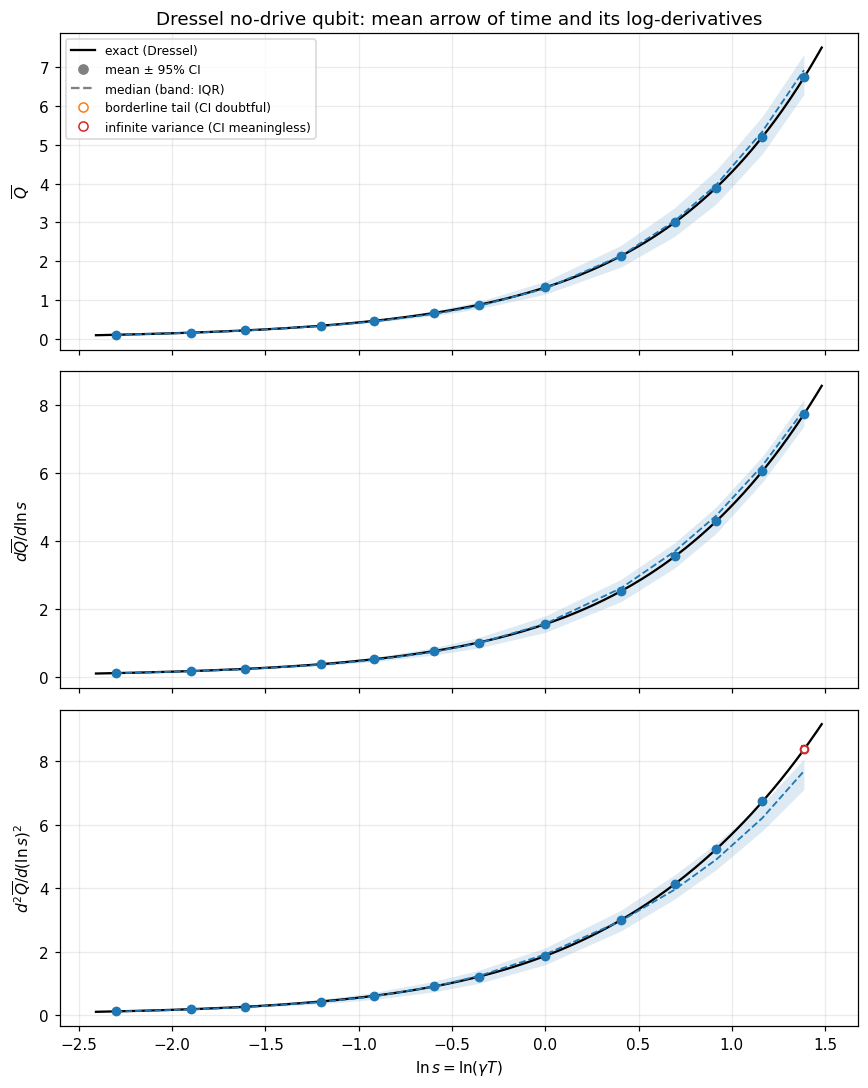

,s,quantity,mean,sem,exact,(mean-exact)/SEM,Hill alpha
0,0.1,Q,0.1047,3.745e-05,0.1047,-1.125,NaN
1,0.1,dQ,0.1091,6.923e-05,0.1091,-1.13,17.05
2,0.1,d2Q,0.1174,0.0001237,0.1175,-1.124,13.99
3,0.15,Q,0.1603,7.78e-05,0.1603,-0.4456,NaN
4,0.15,dQ,0.1697,0.0001399,0.1697,-0.3417,16.88
5,0.15,d2Q,0.1872,0.0002408,0.1872,-0.1722,16.06
6,0.2,Q,0.2179,0.0001317,0.2178,0.3466,NaN
7,0.2,dQ,0.2339,0.00023,0.2338,0.4361,16.64
8,0.2,d2Q,0.263,0.0003807,0.2627,0.5604,18.05
9,0.3,Q,0.3381,0.00026,0.3382,-0.3343,NaN


max |z-score| = 2.00


In [3]:
d_config, d_manifest, d_points, _ = load_run('dressel_scan')
dressel = table(d_points, ('Q', 'dQ', 'd2Q'), np.log)
s_smooth = np.geomspace(0.09, 4.4, 300)
exact = [dressel_no_drive_reference(s) for s in s_smooth]
exact_values = {'Q': [e.mean_Q for e in exact], 'dQ': [e.chi_Q for e in exact], 'd2Q': [e.d2Q_dlog_s2 for e in exact]}

fig, axes = plt.subplots(3, 1, figsize=(8, 10), sharex=True)
for ax, field in zip(axes, ('Q', 'dQ', 'd2Q')):
    ax.plot(np.log(s_smooth), exact_values[field], color='black', lw=1.5, label='exact (Dressel)')
    draw(ax, dressel, field, COLOR['dressel'], label='direct tangent')
    ax.set_ylabel({'Q': r'$\overline{Q}$', 'dQ': r"$d\overline{Q}/d\ln s$", 'd2Q': r"$d^2\overline{Q}/d(\ln s)^2$"}[field])
axes[0].legend(handles=[Line2D([], [], color='black', label='exact (Dressel)')] + LEGEND, fontsize=8, loc='upper left')
axes[-1].set_xlabel(r'$\ln s = \ln(\gamma T)$')
axes[0].set_title('Dressel no-drive qubit: mean arrow of time and its log-derivatives')
fig.tight_layout()
fig.savefig(FIGURES / 'fig1_dressel_Q_derivatives.png', dpi=150)
fig.savefig(FIGURES / 'fig1_dressel_Q_derivatives.pdf')
plt.show()

check = []
for (s, data), e in zip(d_points, [dressel_no_drive_reference(s) for s, _ in d_points]):
    for field, ref in (('Q', e.mean_Q), ('dQ', e.chi_Q), ('d2Q', e.d2Q_dlog_s2)):
        row = dressel[(dressel.param == s) & (dressel.quantity == field)].iloc[0]
        check.append({'s': s, 'quantity': field, 'mean': row['mean'], 'sem': row['sem'], 'exact': ref,
                      '(mean-exact)/SEM': (row['mean'] - ref) / row['sem'], 'Hill alpha': row['alpha']})
dressel_check = pd.DataFrame(check)
with pd.option_context('display.float_format', '{:.4g}'.format, 'display.width', 160):
    display(dressel_check)
print('max |z-score| =', f"{np.max(np.abs(dressel_check['(mean-exact)/SEM'])):.2f}")

### Terminal arrow-of-time distribution at $s=0.1$ (Dressel Fig. 4)

$2^{20}$ trajectories. $\ln\mathcal R=-\ln(1-z_T^2)$ is computed from the final state, so
$P_{\rm err}=P(\ln\mathcal R<0)=0$ by construction (Dressel's 0.7% came from evaluating the
record-based functional with finite bins).

,bin,observed,analytic,z
0,"[0, 0.001)",0.075576,0.075790,-0.827606
1,"[0.001, 0.005)",0.092967,0.092726,0.850264
2,"[0.005, 0.01)",0.067726,0.068131,-1.644102
3,"[0.01, 0.02)",0.093367,0.093377,-0.037196
4,"[0.02, 0.05)",0.171165,0.170744,1.147584
5,"[0.05, 0.1)",0.162039,0.162148,-0.304318
6,"[0.1, 0.2)",0.166504,0.166378,0.345952
7,"[0.2, 0.5)",0.144703,0.144639,0.186995
8,"[0.5, 1)",0.024920,0.025058,-0.902049


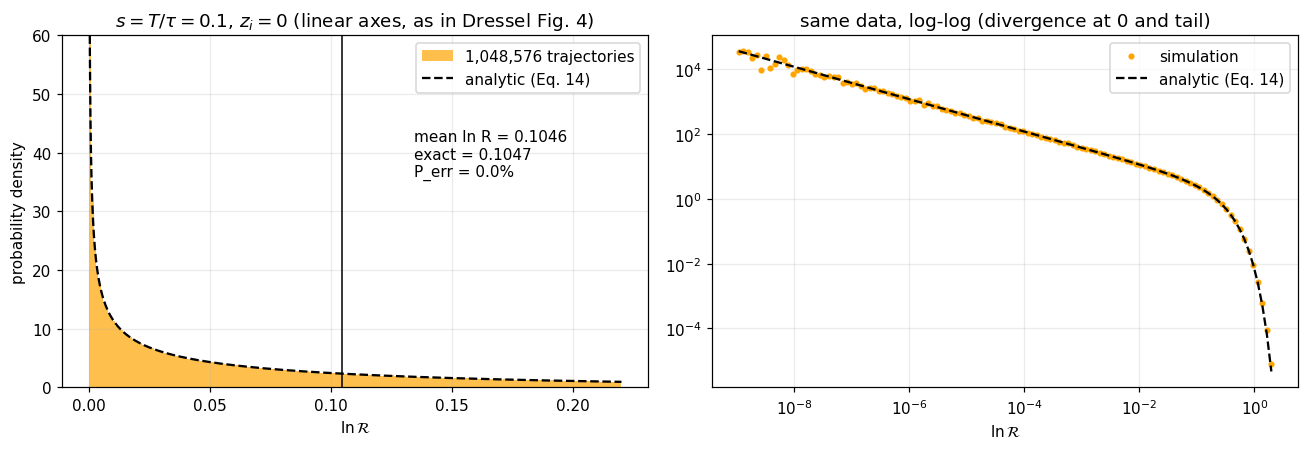

In [4]:
_, _, h_points, _ = load_run('dressel_histogram')
s_hist, h_data = h_points[0]
lnR = dressel_Q_from_final_z(h_data['final_z'])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
bins = np.linspace(0, 0.22, 221)
# Normalize by ALL trajectories (density=True would renormalize to the plotted range only).
counts, edges = np.histogram(lnR, bins=bins)
axes[0].stairs(counts / (lnR.size * np.diff(edges)), edges, fill=True, color='orange', alpha=0.7,
               label=f'{lnR.size:,} trajectories')
grid = np.linspace(1e-5, 0.22, 2000)
axes[0].plot(grid, dressel_no_drive_pdf(grid, s_hist), 'k--', lw=1.5, label='analytic (Eq. 14)')
mean_exact = dressel_no_drive_reference(s_hist).mean_Q
axes[0].axvline(np.mean(lnR), color='black', lw=1)
axes[0].text(0.6, 0.6, f'mean ln R = {np.mean(lnR):.4f}\nexact = {mean_exact:.4f}\nP_err = {np.mean(lnR < 0):.1%}',
             transform=axes[0].transAxes)
axes[0].set_ylim(0, 60)
axes[0].set_xlabel(r'$\ln\mathcal{R}$'); axes[0].set_ylabel('probability density')
axes[0].set_title(r'$s = T/\tau = 0.1$, $z_i = 0$ (linear axes, as in Dressel Fig. 4)')
axes[0].legend()
log_bins = np.geomspace(max(lnR[lnR > 0].min(), 1e-9), lnR.max(), 120)
counts, edges = np.histogram(lnR, bins=log_bins)
density = counts / (lnR.size * np.diff(edges))
centres = np.sqrt(edges[1:] * edges[:-1])
axes[1].loglog(centres[counts > 0], density[counts > 0], '.', color='orange', label='simulation')
axes[1].loglog(centres, dressel_no_drive_pdf(centres, s_hist), 'k--', label='analytic (Eq. 14)')
axes[1].set_xlabel(r'$\ln\mathcal{R}$'); axes[1].set_title('same data, log-log (divergence at 0 and tail)')
axes[1].legend()
fig.tight_layout()
from scipy.integrate import quad
check_edges = np.array([0, 0.001, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0])
check_counts, _ = np.histogram(lnR, bins=check_edges)
check_rows = []
for a, b, c in zip(check_edges[:-1], check_edges[1:], check_counts):
    p = (quad(lambda x: dressel_no_drive_pdf(x, s_hist), a, b, limit=200)[0] if a > 0
         else 1 - quad(lambda x: dressel_no_drive_pdf(x, s_hist), b, np.inf, limit=400)[0])
    check_rows.append({'bin': f'[{a:g}, {b:g})', 'observed': c / lnR.size, 'analytic': p,
                       'z': (c - lnR.size * p) / np.sqrt(lnR.size * p * (1 - p))})
display(pd.DataFrame(check_rows))
fig.savefig(FIGURES / 'fig1b_dressel_lnR_distribution.png', dpi=150)
fig.savefig(FIGURES / 'fig1b_dressel_lnR_distribution.pdf')
plt.show()

## 2. Driven qubit ($H=J\sigma_y$, $J=1$)

$dt=0.00125$, burn-in time 20, averaging time 10, Rademacher noise, 16,384 trajectories per
point. Black line: exact stationary $q$, $q'$, $q''$ from the transfer operator (shown only
where all grid and step-size checks agree). Top: example $z(t)$ trajectories.

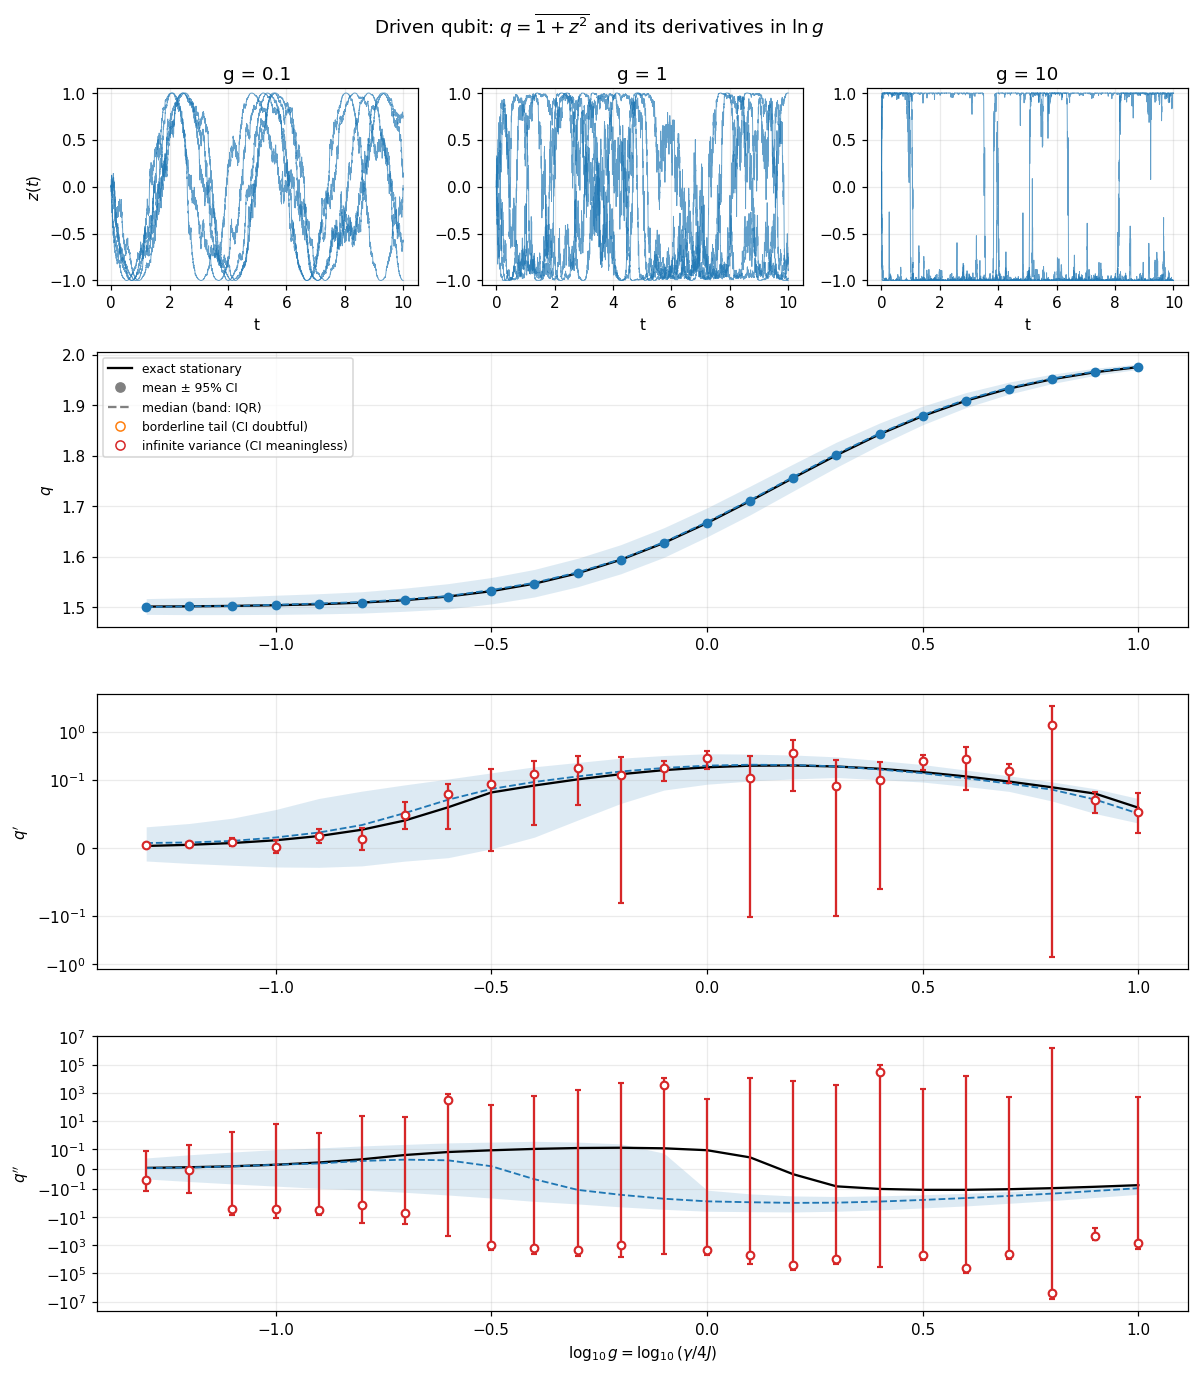

In [5]:
q_config, q_manifest, q_points, q_reference = load_run('driven_qubit')
driven = table(q_points, ('q', 'dq', 'd2q', 'Q', 'dQ', 'd2Q'), np.log10)
ref = {}
for point in (q_reference or {}).get('points', []):
    if point['usable']:
        p = point['preferred']
        ref[np.log10(point['g'])] = {'q': p['q'], 'dq': p['dq_dlog_g'], 'd2q': p['d2q_dlog_g2']}
ref_x = np.array(sorted(ref))

fig = plt.figure(figsize=(11, 12.5))
grid = fig.add_gridspec(4, 3, height_ratios=[1, 1.4, 1.4, 1.4])
for column, g in enumerate((0.1, 1.0, 10.0)):
    ax = fig.add_subplot(grid[0, column])
    _, history = simulate_ensemble(4 * g, rademacher_noise(5, 8000, 11 + column), J=1.0, dt=0.00125,
                                   propagate_tangent=False, store_history=True)
    ax.plot(np.arange(8000) * 0.00125, history['z'].T, lw=0.6, alpha=0.7, color='tab:blue')
    ax.set_title(f'g = {g:g}'); ax.set_ylim(-1.05, 1.05); ax.set_xlabel('t')
    if column == 0:
        ax.set_ylabel(r'$z(t)$')
for row, field in enumerate(('q', 'dq', 'd2q'), start=1):
    ax = fig.add_subplot(grid[row, :])
    if len(ref_x):
        ax.plot(ref_x, [ref[x][field] for x in ref_x], color='black', lw=1.5, label='exact stationary')
    draw(ax, driven, field, COLOR['driven qubit'], label='direct tangent', symlog=None if field == 'q' else 0.05)
    if field != 'q':
        symlog_ticks(ax, 0.05)
    ax.set_ylabel(LABEL[field])
    if row == 1:
        ax.legend(handles=[Line2D([], [], color='black', label='exact stationary')] + LEGEND, fontsize=8, loc='upper left')
    if row == 3:
        ax.set_xlabel(r'$\log_{10} g = \log_{10}(\gamma/4J)$')
fig.suptitle(r"Driven qubit: $q=\overline{1+z^2}$ and its derivatives in $\ln g$", y=0.995)
fig.tight_layout()
fig.savefig(FIGURES / 'fig2_driven_qubit.png', dpi=150)
fig.savefig(FIGURES / 'fig2_driven_qubit.pdf')
plt.show()

## 3. Monitored Ising chains, $L=2$ and $L=8$

Periodic chain, $J=1$, $dt=0.00125$, burn-in time 5, averaging time 10 (the frozen protocol),
Gaussian noise; 2,048 ($L=2$) and 512 ($L=8$) trajectories per point. Top: site-0 $z(t)$ for
example $L=8$ trajectories, as in the article's Fig. 3. $L=2$ points are shifted slightly
left and $L=8$ right for visibility.

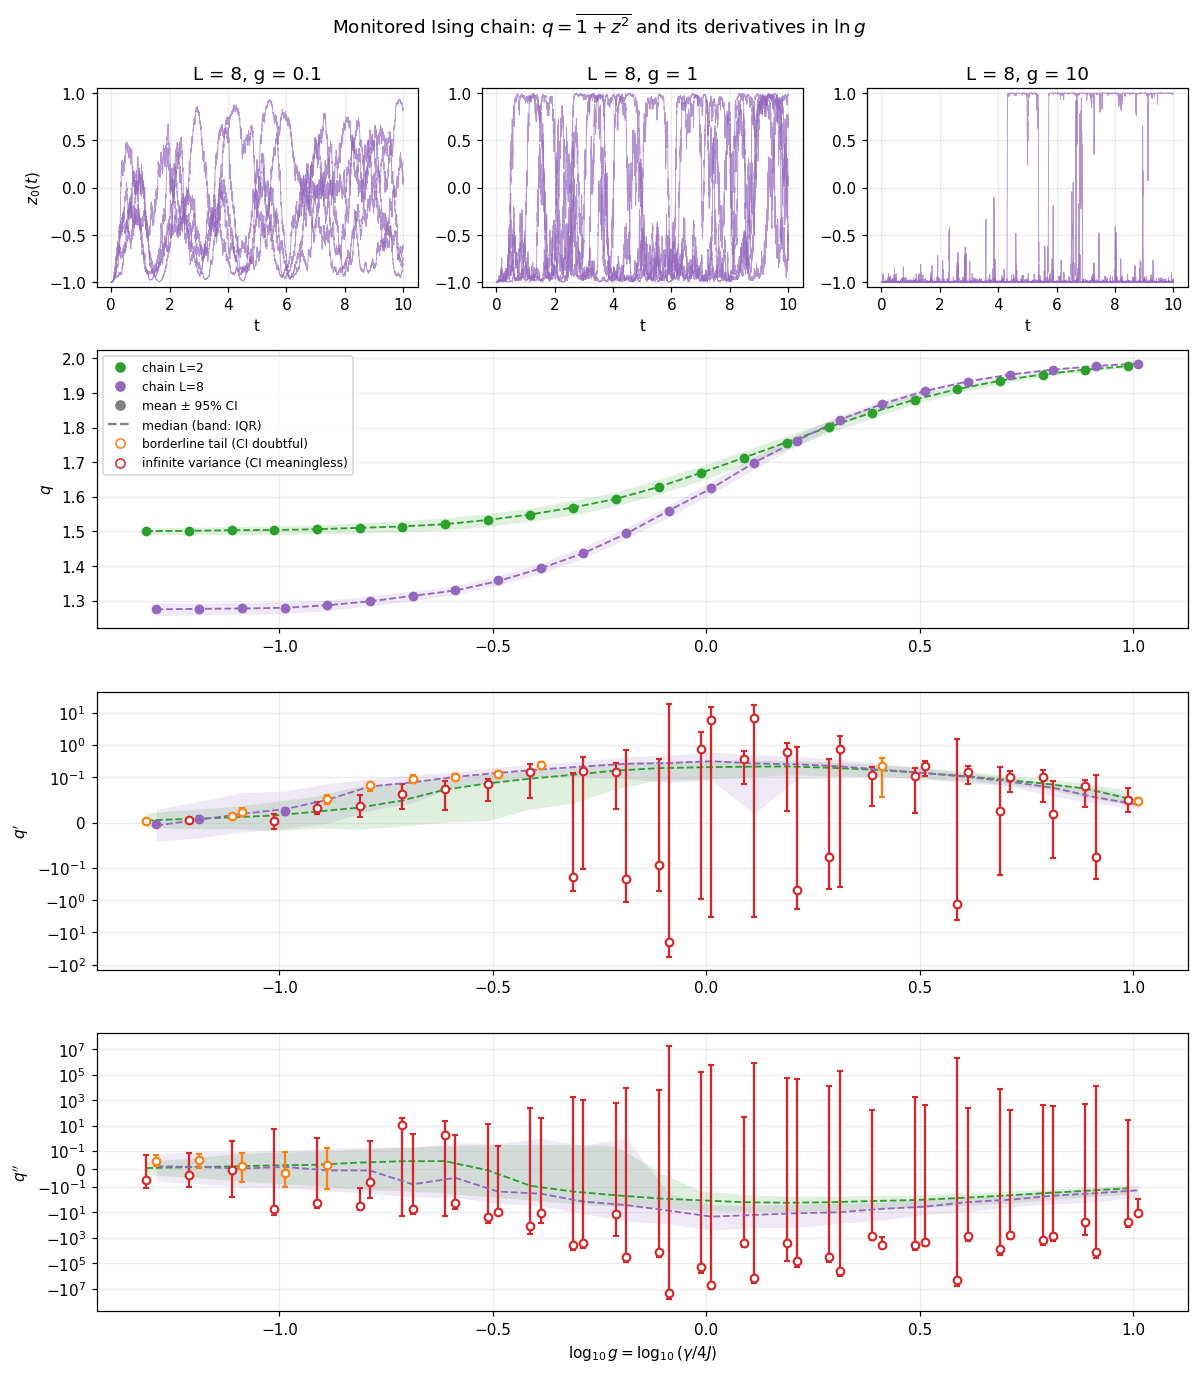

In [6]:
chains = {}
for name, label in (('chain_L2', 'chain L=2'), ('chain_L8', 'chain L=8')):
    config, manifest, points, _ = load_run(name)
    chains[label] = table(points, ('q', 'dq', 'd2q', 'Q', 'dQ', 'd2Q'), np.log10)

fig = plt.figure(figsize=(11, 12.5))
grid = fig.add_gridspec(4, 3, height_ratios=[1, 1.4, 1.4, 1.4])
for column, g in enumerate((0.1, 1.0, 10.0)):
    ax = fig.add_subplot(grid[0, column])
    result = simulate_gaussian_orbital_chain(L=8, gamma=4 * g, J=1.0, dt=0.00125, n_burnin=0, n_samples=8000,
                                             boundary='periodic', n_trajectories=5, seed=21 + column)
    ax.plot(np.arange(8001) * 0.00125, result.z_history[:, :, 0].T, lw=0.6, alpha=0.7, color='tab:purple')
    ax.set_title(f'L = 8, g = {g:g}'); ax.set_ylim(-1.05, 1.05); ax.set_xlabel('t')
    if column == 0:
        ax.set_ylabel(r'$z_0(t)$')
for row, field in enumerate(('q', 'dq', 'd2q'), start=1):
    ax = fig.add_subplot(grid[row, :])
    for label, offset in (('chain L=2', -0.012), ('chain L=8', 0.012)):
        draw(ax, chains[label], field, COLOR[label], offset=offset, label=label,
             symlog=None if field == 'q' else 0.05)
    if field != 'q':
        symlog_ticks(ax, 0.05)
    ax.set_ylabel(LABEL[field])
    if row == 1:
        ax.legend(handles=[Line2D([], [], marker='o', ls='', color=COLOR[k], label=k) for k in chains] + LEGEND,
                  fontsize=8, loc='upper left')
    if row == 3:
        ax.set_xlabel(r'$\log_{10} g = \log_{10}(\gamma/4J)$')
fig.suptitle(r"Monitored Ising chain: $q=\overline{1+z^2}$ and its derivatives in $\ln g$", y=0.995)
fig.tight_layout()
fig.savefig(FIGURES / 'fig3_chains.png', dpi=150)
fig.savefig(FIGURES / 'fig3_chains.pdf')
plt.show()

In [7]:
# Burn-in check for L=2: anchors rerun with burn-in time 20 (independent seeds).
_, _, check_points, _ = load_run('chain_L2_burnin20')
base = {round(np.log10(g), 6): data for g, data in load_run('chain_L2')[2]}
rows = []
for g, data in check_points:
    reference = base[round(np.log10(g), 6)]
    for field in ('q', 'dq', 'd2q'):
        a, b = stats(reference[field], tail=False), stats(data[field], tail=False)
        rows.append({'g': g, 'quantity': LABEL[field], 'burn-in 5': a['mean'], 'burn-in 20': b['mean'],
                     'shift / combined SEM': (b['mean'] - a['mean']) / np.hypot(a['sem'], b['sem'])})
burnin_check = pd.DataFrame(rows)
with pd.option_context('display.float_format', '{:.4g}'.format):
    display(burnin_check)

,g,quantity,burn-in 5,burn-in 20,shift / combined SEM
0,0.1,$q$,1.503,1.504,0.6599
1,0.1,$q'$,0.001976,0.01013,0.8133
2,0.1,$q''$,-5.188,-1.637,0.3142
3,1,$q$,1.668,1.667,-0.7464
4,1,$q'$,0.7534,0.3514,-0.4638
5,1,$q''$,-1.838e+05,-212.3,1.09
6,10,$q$,1.976,1.976,-0.4505
7,10,$q'$,0.03179,0.03642,0.4316
8,10,$q''$,-52.23,-73.83,-0.3801


## 4. Extensive form: $Q$, $Q'$, $Q''$

$Q=\gamma LT\,q$ grows like $\gamma$, so $Q$ is drawn on a log axis and $Q'$, $Q''$ on
symmetric-log axes. The explicit $\gamma$-prefactor terms dominate $Q'$ and $Q''$ wherever
the state response ($q'$, $q''$) is small; per-trajectory values include those terms exactly.

*Caveat on the tail flags in this figure.* Because $Q'=\gamma LT(q+q')$, the well-behaved
$q$ term dominates the largest 5% of $|Q'|$ at weak measurement, so the Hill flag can read
"stable" for $Q'$ where the underlying $q'$ is heavy-tailed. The flags on the intensive
$q'$, $q''$ (Sections 2–3) are the authoritative ones.

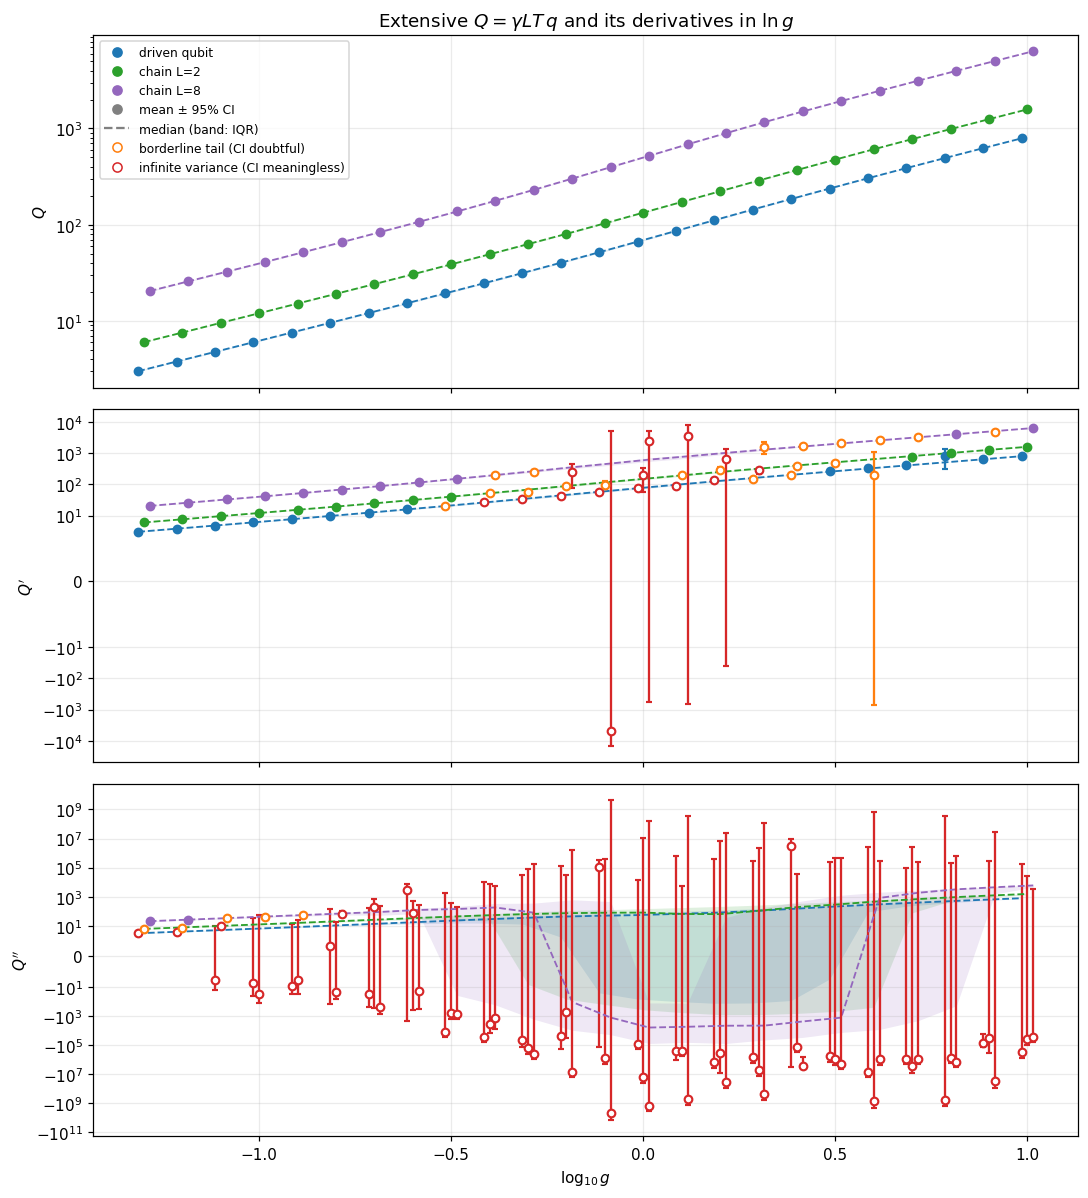

In [8]:
systems = {'driven qubit': driven, **chains}
fig, axes = plt.subplots(3, 1, figsize=(10, 11), sharex=True)
for ax, field in zip(axes, ('Q', 'dQ', 'd2Q')):
    for (label, frame), offset in zip(systems.items(), (-0.015, 0.0, 0.015)):
        draw(ax, frame, field, COLOR[label], offset=offset, label=label, symlog=None if field == 'Q' else 1.0)
    if field == 'Q':
        ax.set_yscale('log')
    else:
        symlog_ticks(ax, 1.0)
    ax.set_ylabel(LABEL[field])
axes[0].legend(handles=[Line2D([], [], marker='o', ls='', color=COLOR[k], label=k) for k in systems] + LEGEND,
               fontsize=8, loc='upper left')
axes[-1].set_xlabel(r'$\log_{10} g$')
axes[0].set_title(r'Extensive $Q=\gamma L T\,q$ and its derivatives in $\ln g$')
fig.tight_layout()
fig.savefig(FIGURES / 'fig4_extensive_Q.png', dpi=150)
fig.savefig(FIGURES / 'fig4_extensive_Q.pdf')
plt.show()

## 5. Summary table

One row per system, point and intensive quantity. `flag` is `unstable` when the Hill tail
index of the per-trajectory values has a 95% upper bound below 2 (infinite variance).

In [9]:
frames = []
for label, frame in (('dressel (Q-form)', dressel), ('driven qubit', driven), *chains.items()):
    part = frame[frame.quantity.isin(('q', 'dq', 'd2q', 'Q', 'dQ', 'd2Q'))].copy()
    if label != 'dressel (Q-form)':
        part = part[part.quantity.isin(('q', 'dq', 'd2q'))]
    part.insert(0, 'system', label)
    frames.append(part)
summary = pd.concat(frames, ignore_index=True)
summary.to_csv(FIGURES / 'summary.csv', index=False)
counts = summary[summary.quantity.isin(('dq', 'd2q', 'dQ', 'd2Q'))].groupby(['system', 'quantity']).flag.value_counts().unstack(fill_value=0)
display(counts)
with pd.option_context('display.float_format', '{:.4g}'.format, 'display.width', 200, 'display.max_rows', 400):
    display(summary[['system', 'x', 'quantity', 'N', 'mean', 'ci', 'median', 'alpha', 'alpha_high', 'max share', 'flag']])

flag                       borderline  stable  unstable
system           quantity                              
chain L=2        d2q                0       0        24
                 dq                 2       0        22
chain L=8        d2q                5       0        19
                 dq                 9       3        12
dressel (Q-form) d2Q                0      12         1
                 dQ                 0      13         0
driven qubit     d2q                0       0        24
                 dq                 0       0        24

,system,x,quantity,N,mean,ci,median,alpha,alpha_high,max share,flag
0,dressel (Q-form),-2.303,Q,16384,0.1047,7.34e-05,0.1029,NaN,NaN,8.244e-05,stable
1,dressel (Q-form),-2.303,dQ,16384,0.1091,0.0001357,0.1059,17.05,17.92,9.387e-05,stable
2,dressel (Q-form),-2.303,d2Q,16384,0.1174,0.0002425,0.1118,13.99,14.77,0.0001052,stable
3,dressel (Q-form),-1.897,Q,16384,0.1603,0.0001525,0.1567,NaN,NaN,8.469e-05,stable
4,dressel (Q-form),-1.897,dQ,16384,0.1697,0.0002742,0.1636,16.88,17.76,9.455e-05,stable
5,dressel (Q-form),-1.897,d2Q,16384,0.1872,0.000472,0.1773,16.06,17.18,0.0001018,stable
6,dressel (Q-form),-1.609,Q,16384,0.2179,0.0002581,0.2119,NaN,NaN,9.226e-05,stable
7,dressel (Q-form),-1.609,dQ,16384,0.2339,0.0004508,0.2241,16.64,17.53,9.858e-05,stable
8,dressel (Q-form),-1.609,d2Q,16384,0.263,0.0007462,0.2484,18.05,19.38,9.915e-05,stable
9,dressel (Q-form),-1.204,Q,16384,0.3381,0.0005096,0.3268,NaN,NaN,8.957e-05,stable


In [10]:
# Consistency of the base observable with the exact stationary reference (driven qubit).
rows = []
for g, data in q_points:
    x = np.log10(g)
    if x in ref:
        s = stats(data['q'], tail=False)
        rows.append({'log10 g': x, 'sampled q': s['mean'], 'SEM': s['sem'], 'stationary q': ref[x]['q'],
                     'z-score': (s['mean'] - ref[x]['q']) / s['sem']})
q_consistency = pd.DataFrame(rows)
with pd.option_context('display.float_format', '{:.5g}'.format):
    display(q_consistency)
print('max |z-score| =', f"{np.max(np.abs(q_consistency['z-score'])):.2f}" if len(q_consistency) else 'n/a',
      f'over {len(q_consistency)} of {len(q_points)} points with a usable reference')

,log10 g,sampled q,SEM,stationary q,z-score
0,-1.3,1.5008,0.00016958,1.5009,-0.55879
1,-1.2,1.5015,0.00018339,1.5014,0.60767
2,-1.1,1.502,0.00019774,1.5023,-1.2822
3,-1,1.5038,0.00021579,1.5036,0.84096
4,-0.9,1.5059,0.00023092,1.5056,1.1575
5,-0.8,1.5085,0.00024941,1.5088,-1.0742
6,-0.7,1.5135,0.00026891,1.5136,-0.62008
7,-0.6,1.5204,0.00029142,1.5209,-1.7269
8,-0.5,1.5317,0.00030373,1.5314,0.67901
9,-0.4,1.5462,0.00032017,1.5464,-0.67929


max |z-score| = 1.73 over 24 of 24 points with a usable reference


## 7. Status (from the numbers above)

**1. The base observable $q$ (and $Q$) is fully under control in every system.**

* Driven qubit: the sampled $q$ matches the exact stationary value at all 24 points
  (largest deviation 1.73 standard errors).
* Dressel no-drive: $Q$ matches the analytic result at all 13 points.
* $L=8$ chain: $q$ agrees with the independent earlier stationarity study at the anchors
  ($1.2804$ vs $1.2785$, $1.626$ vs $1.623$, $1.9848$ vs $1.9845$ at $g=0.1, 1, 10$).
* $L=2$ burn-in check: extending burn-in from 5 to 20 shifts $q$ by less than one combined
  standard error at all three anchors.
* The chain crossover is clearly visible: $q$ rises from $1.50$ ($L=2$) or $1.27$ ($L=8$)
  at weak measurement to $1.98$ at $g=10$, more sharply for $L=8$, centred near $\log g=0$.

**2. Without a drive, the direct derivatives work.** In the Dressel case $Q'$ and $Q''$ agree
with the exact analytic derivatives at every point (all 39 comparisons within 2.0 standard
errors). Only the strongest point ($s=4$) shows a thickening $Q''$ tail (tail index 1.55),
although its mean is still correct.

**3. With a drive, the direct derivatives are not usable as averages.**

* Driven qubit, where the exact answer is known: $q'$ is smooth and peaks at about $0.20$
  near $g\approx1.6$; $q''$ is small, changing sign from $+0.13$ (near $g\approx0.6$) to
  $-0.12$ (near $g\approx3.5$).
  * $q'$: per-trajectory values have infinite variance at all 24 points (tail index
    0.98–1.73). The means scatter around the exact curve with large, unreliable error bars.
  * $q''$: infinite variance at all 24 points (tail index 0.5–0.9). The means are off by
    up to seven orders of magnitude, e.g. $-2153\pm2500$ at $g=1$ against an exact $+0.084$.
* Chains:
  * $q''$ is flagged at every point: $L=2$ is unstable at 24/24; $L=8$ is unstable at 19
    and borderline at 5 (the weakest-measurement points).
  * The means reach $|q''|\sim10^6$–$10^7$ near $g\approx1$, e.g. $L=8$, $g=1$:
    $-4.8\times10^6\pm5.3\times10^6$.
  * $q'$ is usable only at the weakest measurement for $L=8$ (3 stable points, e.g.
    $q'=0.0156\pm0.0051$ at $g=0.1$) and is heavy-tailed elsewhere.

**4. Medians are shown for context only.** They describe the bulk of the per-trajectory values
but are not estimates of the derivative of the average: for the driven qubit the median of
$q''$ sits near $-0.5$ around $g\approx1$ while the exact value is $+0.08$.

**Bottom line.** The simulation and the tangent algebra are correct, and $q(g)$ is reliable
everywhere. Averaging per-trajectory pathwise derivatives does not give usable $q'$ or $q''$
once the qubit is driven, at any $g$ studied. A direct estimator that holds the measurement
record fixed and adds a likelihood-ratio term is the proposed fix; a 256-trajectory premise
test at $L=8$, $g=1$ showed bounded, light-tailed per-trajectory derivatives in that form. It
has not yet been derived, implemented, or validated.